# Dữ liệu văn bản — lựa chọn tập dữ liệu và EDA

**Nhóm T&D** · Trần Hữu Anh Triết (2470745), Ngô Minh Đại (2470722)

**Học phần:** Nền tảng lập trình cho phân tích và trực quan dữ liệu · Học kỳ 261, năm học 2026–2027 · Giảng viên Lê Thành Sách

Checkpoint này chọn tập dữ liệu văn bản và làm phần EDA: mô tả tập, đối chiếu ràng buộc, cân bằng nhãn, phân phối độ dài, trùng lặp/thiếu, và từ vựng phân biệt lớp. Chưa vector hoá, chưa huấn luyện mô hình, chưa confusion matrix — các phần đó ở checkpoint sau. Notebook chạy được trên Google Colab (Run all).

## 1. Bài toán

Cho một **đoạn văn** về thuế – hoá đơn điện tử, dự đoán nó thuộc **chuyên mục** nào:

- `hoi_dap_tin_tuc` — hỏi–đáp, tin chính sách, tình huống nghiệp vụ.
- `quy_dinh` — cách lập/gửi/lưu trữ/điều chỉnh/xử lý sai sót hoá đơn.
- `van_ban` — diễn giải nội dung Nghị định/Thông tư.

Đây là bài toán **phân loại văn bản tiếng Việt đa lớp**. Phần EDA này mô tả dữ liệu và chỉ ra độ khó (mất cân bằng lớp, độ dài biến thiên, từ vựng chồng lấn giữa các lớp).

## 2. Tập dữ liệu

Tập **tự thu thập và biên tập**: các bài viết tri thức thuế – kế toán – hoá đơn điện tử (tiếng Việt), đã làm sạch (bỏ HTML, quảng cáo, thông tin thương hiệu) và tách thành **đoạn văn**. Mỗi đoạn là một mẫu, nhãn là chuyên mục của bài gốc.

- Ngôn ngữ: tiếng Việt (khuyến khích theo đề).
- Tự thu thập: dữ liệu do nhóm crawl và biên tập, không phải tập có sẵn.
- Không chứa thông tin cá nhân/định danh; chỉ là nội dung quy định công khai.
- File dữ liệu công khai trong repo: `notebooks/data/text_corpus.csv`.

In [1]:
# Cài thư viện còn thiếu (Colab thường đã có pandas/sklearn/matplotlib/seaborn/wordcloud)
import importlib, subprocess, sys
for pkg, mod in [("pyvi", "pyvi"), ("wordcloud", "wordcloud")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

import re, io, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib
import seaborn as sns
from collections import Counter

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
# DejaVu Sans (mặc định của matplotlib) hỗ trợ dấu tiếng Việt
matplotlib.rcParams["font.family"] = "DejaVu Sans"

# Đọc dữ liệu: ưu tiên file cục bộ, nếu không có thì tải từ GitHub raw (để chạy trên Colab)
LOCAL = "data/text_corpus.csv"
RAW = "https://raw.githubusercontent.com/tobitran17-art/CO5177/main/notebooks/data/text_corpus.csv"
try:
    df = pd.read_csv(LOCAL)
    print("Đọc từ local:", LOCAL)
except FileNotFoundError:
    df = pd.read_csv(RAW)
    print("Đọc từ GitHub raw")
df["text"] = df["text"].astype(str)
print("Kích thước:", df.shape)
df.head(3)

Đọc từ local: data/text_corpus.csv
Kích thước: (2392, 5)


,post_id,category,date,n_char,text
0,15719,hoi_dap_tin_tuc,2026-09-09,151,"Tháng 9/2026, doanh nghiệp và kế toán cần lưu ..."
1,15719,hoi_dap_tin_tuc,2026-09-09,166,Đáng chú ý có **Luật Tiếp cận thông tin 2026**...
2,15719,hoi_dap_tin_tuc,2026-09-09,160,"Trong đó, ba văn bản có hiệu lực trong tháng 9..."


## 3. Đối chiếu ràng buộc

Đề yêu cầu dữ liệu văn bản: ít nhất **2.000 mẫu**, ưu tiên **tiếng Việt**, và **tự thu thập** được đánh giá cao.

In [2]:
n = len(df)
n_classes = df["category"].nunique()
check = pd.DataFrame([
    ["Số mẫu", "≥ 2.000", f"{n:,} đoạn", "Đạt" if n >= 2000 else "Chưa"],
    ["Ngôn ngữ", "Ưu tiên tiếng Việt", "Tiếng Việt", "Đạt"],
    ["Tự thu thập", "Khuyến khích", "Crawl + biên tập", "Đạt"],
    ["Số lớp", "≥ 2 (phân loại)", f"{n_classes} lớp", "Đạt"],
], columns=["Ràng buộc", "Yêu cầu", "Tập này", "Đạt"])
check

,Ràng buộc,Yêu cầu,Tập này,Đạt
0,Số mẫu,≥ 2.000,"2,392 đoạn",Đạt
1,Ngôn ngữ,Ưu tiên tiếng Việt,Tiếng Việt,Đạt
2,Tự thu thập,Khuyến khích,Crawl + biên tập,Đạt
3,Số lớp,≥ 2 (phân loại),3 lớp,Đạt


## 4. Cân bằng nhãn

Số mẫu mỗi chuyên mục chênh lệch — lớp `hoi_dap_tin_tuc` nhiều nhất, `van_ban` ít nhất. Đây là dữ liệu **mất cân bằng**, cần lưu ý khi chia tập và chọn chỉ số đánh giá (macro-F1 thay vì accuracy).

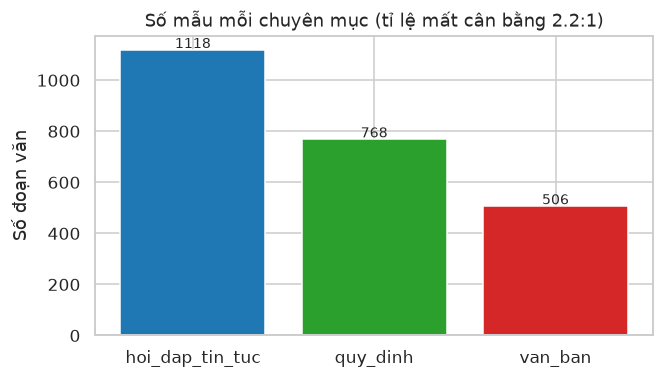

Kết luận: lớp lớn nhất gấp 2.2 lần lớp nhỏ nhất -> cần macro-F1 và cân nhắc class_weight.


In [3]:
counts = df["category"].value_counts()
ratio = counts.max() / counts.min()
fig, ax = plt.subplots(figsize=(6.2, 3.6))
bars = ax.bar(counts.index, counts.values, color=["#1f77b4", "#2ca02c", "#d62728"])
ax.set_title(f"Số mẫu mỗi chuyên mục (tỉ lệ mất cân bằng {ratio:.1f}:1)")
ax.set_ylabel("Số đoạn văn")
for b, v in zip(bars, counts.values):
    ax.text(b.get_x()+b.get_width()/2, v+8, f"{v}", ha="center", fontsize=9)
plt.tight_layout(); plt.show()
print("Kết luận: lớp lớn nhất gấp %.1f lần lớp nhỏ nhất -> cần macro-F1 và cân nhắc class_weight." % ratio)

## 5. Phân phối độ dài văn bản

Độ dài đoạn (số ký tự và số token) cho biết nên cắt/ghép ra sao khi vector hoá. Phân phối lệch phải: nhiều đoạn ngắn, một số đoạn rất dài.

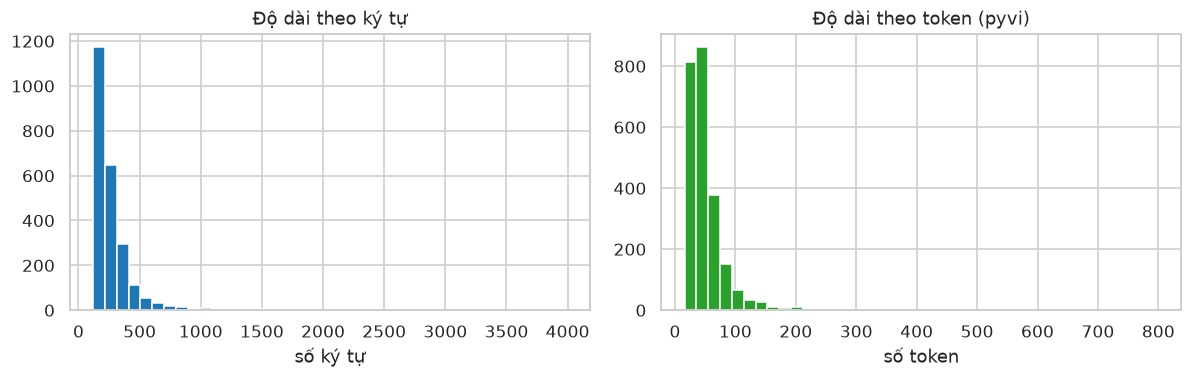

       n_char  n_token
count  2392.0   2392.0
mean    274.2     54.0
std     228.8     47.8
min     120.0     16.0
25%     160.0     31.0
50%     220.0     43.0
75%     309.0     60.0
max    3989.0    799.0

Kết luận: median ~43 token; phân phối lệch phải -> dùng TF-IDF có max_features và loại đoạn quá ngắn.


In [4]:
from pyvi import ViTokenizer
df["n_char"] = df["text"].str.len()
df["n_token"] = df["text"].apply(lambda t: len(ViTokenizer.tokenize(t).split()))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(df["n_char"], bins=40, color="#1f77b4"); axes[0].set_title("Độ dài theo ký tự"); axes[0].set_xlabel("số ký tự")
axes[1].hist(df["n_token"], bins=40, color="#2ca02c"); axes[1].set_title("Độ dài theo token (pyvi)"); axes[1].set_xlabel("số token")
plt.tight_layout(); plt.show()
print(df[["n_char", "n_token"]].describe().round(1).to_string())
print("\nKết luận: median ~%d token; phân phối lệch phải -> dùng TF-IDF có max_features và loại đoạn quá ngắn." % df["n_token"].median())

## 6. Trùng lặp và thiếu

Kiểm tra đoạn rỗng, trùng lặp y hệt (gây rò rỉ giữa train/test nếu không khử).

In [5]:
n_empty = int((df["text"].str.strip() == "").sum())
n_dup = int(df["text"].duplicated().sum())
dup_by_cat = df[df["text"].duplicated(keep=False)].groupby("category").size()
print(f"Đoạn rỗng: {n_empty}")
print(f"Đoạn trùng y hệt: {n_dup} ({n_dup/len(df)*100:.1f}%)")
print("Trùng theo lớp:\n", dup_by_cat.to_string() if len(dup_by_cat) else "  (không có)")
print("\nKết luận: khử trùng trước khi chia tập để tránh rò rỉ dữ liệu (data leakage).")

Đoạn rỗng: 0
Đoạn trùng y hệt: 5 (0.2%)
Trùng theo lớp:
 category
hoi_dap_tin_tuc    2
quy_dinh           4
van_ban            4

Kết luận: khử trùng trước khi chia tập để tránh rò rỉ dữ liệu (data leakage).


## 7. Từ vựng và từ phân biệt lớp

Tách từ tiếng Việt bằng `pyvi`, bỏ stopword, đếm từ. Mỗi lớp có những từ đặc trưng riêng — nhưng nhiều từ ("hóa đơn", "doanh nghiệp", "thuế") xuất hiện ở mọi lớp, cho thấy ranh giới lớp **chồng lấn** → bài toán không tầm thường.

Kích thước từ vựng: 2932
20 từ phổ biến nhất: ['thuế', 'hóa đơn', 'điện tử', 'doanh nghiệp', 'quy định', 'sử dụng', 'cơ quan', 'ngày', 'phải', 'bán', 'kinh doanh', 'đơn', 'lập', 'nghị định', 'thông tư', 'nộp', 'thực hiện', 'dịch vụ', 'mua', 'nđ']


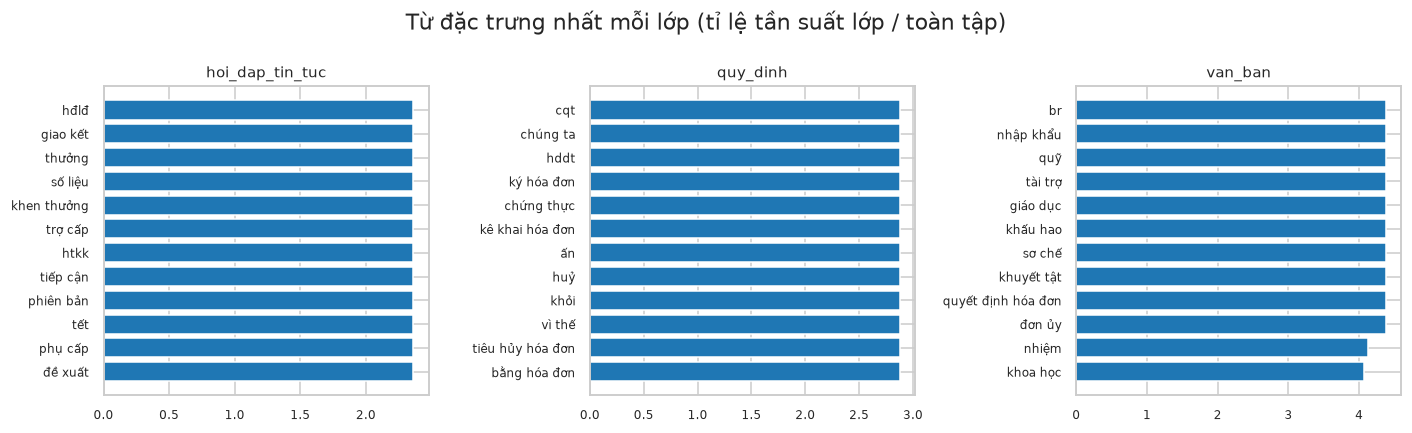

Kết luận: mỗi lớp có nhóm từ riêng, nhưng từ chung ('hóa đơn','thuế') phủ mọi lớp -> cần TF-IDF để hạ trọng số từ phổ biến.


In [6]:
STOP = set('''và của có là các được cho trong đã khi với những một người đến từ theo về
sẽ không này đó ra tại như để trên hoặc còn thì cũng vào nếu bị bởi mà nên rất hơn sau trước
tục việc do nhiều tại vì ông bà rằng cùng số''' .split())

def tokens(t):
    t = ViTokenizer.tokenize(t.lower())
    out = []
    for w in t.split():
        w2 = w.replace("_", " ")
        if w.isalpha() or "_" in w:
            if w2 not in STOP and len(w2) > 1 and not w2.isdigit():
                out.append(w2)
    return out

df["tokens"] = df["text"].apply(tokens)
vocab = Counter(w for toks in df["tokens"] for w in toks)
print("Kích thước từ vựng:", len(vocab))
print("20 từ phổ biến nhất:", [w for w, _ in vocab.most_common(20)])

# từ đặc trưng mỗi lớp: tần suất trong lớp / tần suất toàn tập (chuẩn hoá)
overall = Counter(w for toks in df["tokens"] for w in toks)
total_all = sum(overall.values())
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=False)
for ax, cat in zip(axes, ["hoi_dap_tin_tuc", "quy_dinh", "van_ban"]):
    sub = Counter(w for toks in df[df.category==cat]["tokens"] for w in toks)
    tot = sum(sub.values())
    score = {w: (c/tot) / ((overall[w]/total_all)+1e-9) for w, c in sub.items() if c >= 5}
    top = sorted(score.items(), key=lambda x: x[1], reverse=True)[:12]
    ws = [w for w, _ in top][::-1]; vs = [v for _, v in top][::-1]
    ax.barh(ws, vs, color="#1f77b4"); ax.set_title(cat, fontsize=10); ax.tick_params(labelsize=8)
fig.suptitle("Từ đặc trưng nhất mỗi lớp (tỉ lệ tần suất lớp / toàn tập)")
plt.tight_layout(); plt.show()
print("Kết luận: mỗi lớp có nhóm từ riêng, nhưng từ chung ('hóa đơn','thuế') phủ mọi lớp -> cần TF-IDF để hạ trọng số từ phổ biến.")

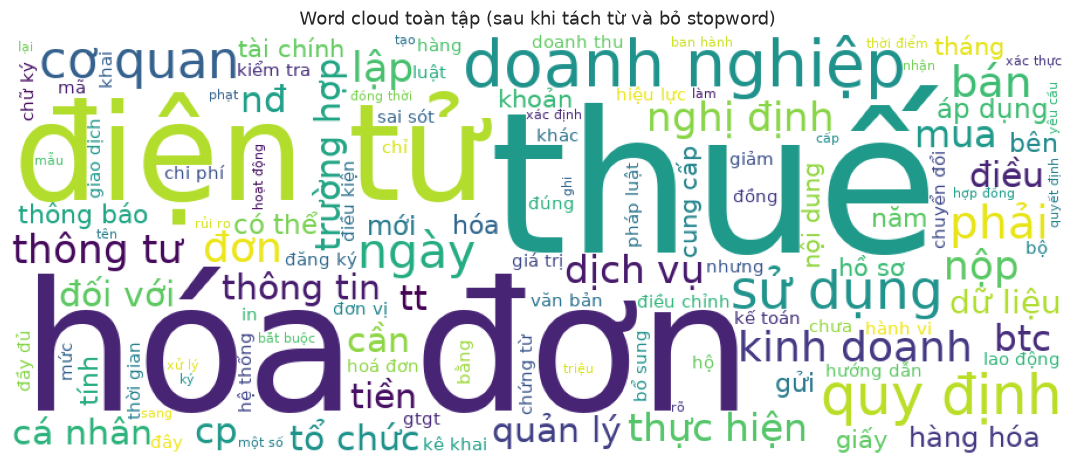

In [7]:
# Word cloud toàn tập (DejaVuSans hỗ trợ dấu tiếng Việt)
from wordcloud import WordCloud
font = matplotlib.font_manager.findfont("DejaVu Sans")
wc = WordCloud(width=900, height=360, background_color="white", font_path=font,
               max_words=120, collocations=False).generate_from_frequencies(vocab)
plt.figure(figsize=(11, 4.4)); plt.imshow(wc); plt.axis("off")
plt.title("Word cloud toàn tập (sau khi tách từ và bỏ stopword)"); plt.tight_layout(); plt.show()

## 8. Nhận xét và phần sau

- Tập **2.392 đoạn** tiếng Việt, 3 lớp, **mất cân bằng** (~2,2:1) — cần macro-F1 và `class_weight`.
- Độ dài lệch phải, có đoạn rất dài → TF-IDF giới hạn `max_features`, lọc đoạn quá ngắn.
- Khử **đoạn trùng** trước khi chia tập để tránh rò rỉ.
- Từ vựng giữa các lớp **chồng lấn** → bài toán có độ khó thực, không tầm thường.

**Phần sau (checkpoint tiếp):** vector hoá TF-IDF (so với embedding), chia train/val/test theo tỉ lệ giữ phân bố lớp, huấn luyện mô hình cơ bản (Logistic Regression, Linear SVM), **confusion matrix kèm ví dụ bị gán sai**, và so sánh với mô hình mở rộng.